# 06 · Supplier & purchase-order risk

**Business problem.** About one purchase order in three is only **partially received**, starving factories and, downstream, branches.
When a buyer drafts a PO we want to answer: *how likely is it to arrive short, and how long will it really take?*

**Models (both use only information known when the PO is drafted – no leakage from delivery dates or status):**
1. **Classifier** – P(partial receipt). HistGradientBoosting, vs. the "supplier's historical rate" baseline.
2. **Regressor** – expected lead time in days (PO date → last line delivered), vs. predicting the average.
3. **Supplier scorecard** – partial-receipt rate with a Wilson confidence interval (so a supplier with 8 POs is not ranked like one with 800).

**Policy suggestion** (from the blueprint): if P(partial) > 0.40, split the PO with a backup supplier of the same material type and add buffer days = predicted − typical lead time.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                       # lets the notebook import the `cottonil` package
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cottonil import config as cfg
from cottonil.data_io import load_table, load_sales_lines, load_product_master, week_start, quick_profile
from cottonil.plotting import setup, NAVY, TEAL, ORANGE, RED, PALETTE
setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

DATA_DIR = cfg.find_data_dir()
SOURCE = cfg.data_source(DATA_DIR)
print(f"Data folder : {DATA_DIR}")
print(f"Data source : {SOURCE.upper()}" + ("   <-- synthetic test data; retrain on real data before trusting any number" if SOURCE == "synthetic" else ""))

Data folder : D:\HVIA Internship\task 2\cottonil-ai\COTTONIL_Data
Data source : REAL


In [2]:
from cottonil import suppliers as SP
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, mean_absolute_error, log_loss
po, items, sup = load_table("purchase_orders"), load_table("purchase_order_items"), load_table("suppliers")
d = SP.build_po_table(po, items, sup)
print(f"{len(d):,} POs | {d.supplier_id.nunique()} suppliers | partial rate {d.partial.mean():.1%} | median lead time {d.lead_days.median():.0f} days")
d.groupby("material_type").agg(pos=("partial", "size"), partial_rate=("partial", "mean"), lead_days=("lead_days", "median")).round(3).sort_values("partial_rate", ascending=False)

41,500 POs | 48 suppliers | partial rate 33.0% | median lead time 42 days


,pos,partial_rate,lead_days
material_type,,,
Packaging,4339,0.339,41.0
Elastic & Lycra,4351,0.339,41.0
Labels,4352,0.335,42.0
Dyes,4264,0.332,41.0
Machinery services,4298,0.331,41.0
Knitted fabric,4305,0.330,42.0
Logistics,3439,0.329,42.0
Cotton yarn,3421,0.329,41.0
Finished garments,4376,0.324,42.0


## 1 · Time-based split
Test = last 12 months of POs, validation = the 12 months before, train = everything earlier.

In [3]:
last = d.po_date.max()
tr, va, te = d[d.po_date <= last - pd.Timedelta(days=730)], d[(d.po_date > last - pd.Timedelta(days=730)) & (d.po_date <= last - pd.Timedelta(days=365))], d[d.po_date > last - pd.Timedelta(days=365)]
maps = SP.fit_maps(d)
Xtr, Xva, Xte = (SP.encode(x, maps) for x in (tr, va, te))
cat_idx = [SP.FEATURES.index(c) for c in SP.CAT_COLS]
print(f"train {len(tr):,} | val {len(va):,} | test {len(te):,}   (test partial rate {te.partial.mean():.1%})")

clf = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_leaf_nodes=12, min_samples_leaf=60, l2_regularization=3.0,
                                     categorical_features=cat_idx, early_stopping=False, random_state=42).fit(Xtr, tr.partial)
ll = [log_loss(va.partial, np.clip(p, 1e-6, 1 - 1e-6)) for p in clf.staged_predict_proba(Xva)]
best = int(np.argmin(ll)) + 1
clf = HistGradientBoostingClassifier(**{**clf.get_params(), "max_iter": best}).fit(Xtr, tr.partial)
print("best #trees:", best)

train 31,270 | val 5,138 | test 5,092   (test partial rate 33.3%)


best #trees: 1


In [4]:
p_te = clf.predict_proba(Xte)[:, 1]; y = te.partial.values
sup_rate = tr.groupby("supplier_id").partial.mean(); p_base = te.supplier_id.map(sup_rate).fillna(tr.partial.mean()).values
def at(p, t): pred = p >= t; return {"alerts": int(pred.sum()), "precision": float(y[pred].mean()) if pred.any() else np.nan, "recall": float(pred[y == 1].mean())}
tab = pd.DataFrame({"HistGB": {"ROC-AUC": roc_auc_score(y, p_te), "PR-AUC": average_precision_score(y, p_te), "Brier": brier_score_loss(y, p_te), **{f"{k}@0.40": v for k, v in at(p_te, .40).items()}},
                    "baseline: supplier's historical rate": {"ROC-AUC": roc_auc_score(y, p_base), "PR-AUC": average_precision_score(y, p_base), "Brier": brier_score_loss(y, p_base), **{f"{k}@0.40": v for k, v in at(p_base, .40).items()}},
                    "no model (always 33%)": {"ROC-AUC": .5, "PR-AUC": y.mean(), "Brier": brier_score_loss(y, np.full(len(y), tr.partial.mean()))}}).T
tab.round(3)

,ROC-AUC,PR-AUC,Brier,alerts@0.40,precision@0.40,recall@0.40
HistGB,0.516,0.342,0.222,0.0,NaN,0.0
baseline: supplier's historical rate,0.500,0.327,0.223,0.0,NaN,0.0
no model (always 33%),0.500,0.333,0.222,NaN,NaN,NaN


In [5]:
# lead-time regressor (predict days from PO date to last delivery)
reg = HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.06, max_iter=400, max_leaf_nodes=12, min_samples_leaf=60, categorical_features=cat_idx,
                                    early_stopping=False, random_state=42).fit(Xtr, tr.lead_days)
mae_v = [mean_absolute_error(va.lead_days, p) for p in reg.staged_predict(Xva)]; bi = int(np.argmin(mae_v)) + 1
reg = HistGradientBoostingRegressor(**{**reg.get_params(), "max_iter": bi}).fit(Xtr, tr.lead_days)
lt = pd.DataFrame({"model": [mean_absolute_error(te.lead_days, reg.predict(Xte))],
                   "baseline: material-type median": [mean_absolute_error(te.lead_days, te.material_type.map(tr.groupby("material_type").lead_days.median()).fillna(tr.lead_days.median()))],
                   "baseline: global median": [mean_absolute_error(te.lead_days, np.full(len(te), tr.lead_days.median()))]}, index=["MAE (days)"]).T
lt.round(2)

,MAE (days)
model,11.06
baseline: material-type median,12.08
baseline: global median,12.09


## 2 · Supplier scorecard (with uncertainty)

In [6]:
sc = d.groupby("supplier_id").agg(material_type=("material_type", "first"), pos=("partial", "size"), partial=("partial", "sum"), spend_m=("po_subtotal_EGP", lambda s: s.sum() / 1e6),
                                  median_lead_days=("lead_days", "median")).reset_index()
sc = sc.merge(sup[["supplier_id", "city_country"]].rename(columns={"city_country": "supplier_city"}), on="supplier_id", how="left")
sc["partial_rate"] = sc.partial / sc.pos
sc["ci_low"], sc["ci_high"] = SP.wilson(sc.partial, sc.pos)
sc["risk_rank_upper"] = sc.ci_high.rank(ascending=False).astype(int)
cfg.save_serving("supplier_scorecard", sc.round(4))
print("sampling noise check: 95% CI width on a typical supplier =", f"{(sc.ci_high - sc.ci_low).median():.1%}", "-> differences much smaller than this may just be noise")
sc.sort_values("partial_rate", ascending=False).head(8).round(3)

sampling noise check: 95% CI width on a typical supplier = 6.3% -> differences much smaller than this may just be noise


,supplier_id,material_type,pos,partial,spend_m,median_lead_days,supplier_city,partial_rate,ci_low,ci_high,risk_rank_upper
13,SUP014,Elastic & Lycra,888,315,646.784,42.0,القاهرة، مصر,0.355,0.324,0.387,1
14,SUP015,Labels,897,316,603.406,42.0,الإسكندرية، مصر,0.352,0.322,0.384,2
17,SUP018,Dyes,873,307,593.866,42.0,بورسعيد، مصر,0.352,0.321,0.384,3
23,SUP024,Elastic & Lycra,875,306,622.232,41.0,الجيزة، مصر,0.350,0.319,0.382,4
30,SUP031,Packaging,850,295,592.702,41.0,دمياط، مصر,0.347,0.316,0.380,5
42,SUP043,Finished garments,838,290,561.959,41.0,المحلة الكبرى، مصر,0.346,0.315,0.379,6
0,SUP001,Packaging,840,290,601.612,41.0,بورسعيد، مصر,0.345,0.314,0.378,7
22,SUP023,Finished garments,925,319,645.700,42.0,المحلة الكبرى، مصر,0.345,0.315,0.376,11


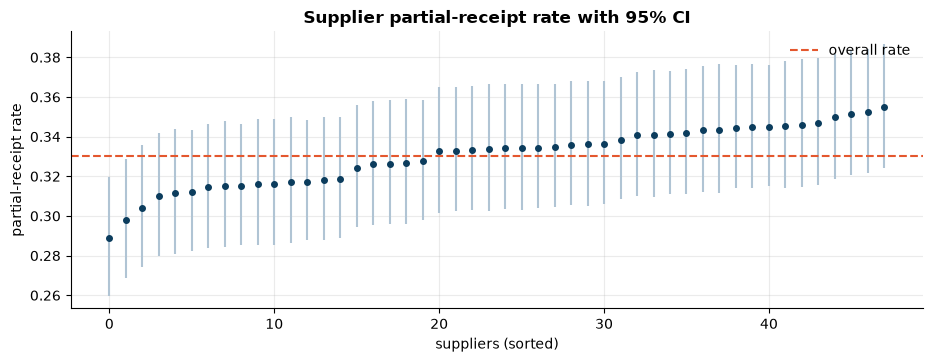

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6)); s = sc.sort_values("partial_rate").reset_index(drop=True)
ax.errorbar(s.index, s.partial_rate, yerr=[s.partial_rate - s.ci_low, s.ci_high - s.partial_rate], fmt="o", color=NAVY, ecolor="#b0c4d4", ms=4)
ax.axhline(d.partial.mean(), color=RED, ls="--", label="overall rate"); ax.set_xlabel("suppliers (sorted)"); ax.set_ylabel("partial-receipt rate"); ax.set_title("Supplier partial-receipt rate with 95% CI"); ax.legend(); plt.show()

## 3 · Refit on all POs and save

In [8]:
Xall = SP.encode(d, maps)
clf_f = HistGradientBoostingClassifier(**{**clf.get_params()}).fit(Xall, d.partial)
reg_f = HistGradientBoostingRegressor(**{**reg.get_params()}).fit(Xall, d.lead_days)
typical = d.groupby("supplier_id").lead_days.median().to_dict()
cfg.save_model("supplier_risk", {"clf": clf_f, "reg": reg_f, "maps": maps, "features": SP.FEATURES, "threshold": 0.40, "typical_lead_days": typical,
                                 "overall_partial_rate": float(d.partial.mean()), "data_source": SOURCE})
cfg.save_serving("po_history_summary", d.assign(ym=d.po_date.dt.to_period("M").astype(str)).groupby(["ym", "material_type"]).agg(pos=("partial", "size"), partial_rate=("partial", "mean")).reset_index().round(4))
cfg.save_metrics("06_supplier_risk", {"test_partial_rate": float(y.mean()), "model": tab.loc["HistGB"].round(4).to_dict(), "baseline": tab.loc["baseline: supplier's historical rate"].round(4).to_dict(),
                                      "lead_time_mae": lt["MAE (days)"].round(3).to_dict(), "median_ci_width": float((sc.ci_high - sc.ci_low).median())}, DATA_DIR)
example = d.sample(1, random_state=3)
print("example PO -> P(partial) = %.2f | predicted lead %.0f days | actual: %s, %d days" % (clf_f.predict_proba(SP.encode(example, maps))[0, 1], reg_f.predict(SP.encode(example, maps))[0], example.po_status.iloc[0], example.lead_days.iloc[0]))

example PO -> P(partial) = 0.33 | predicted lead 48 days | actual: Received, 15 days


## Takeaways
* Judge the classifier by whether it beats **the supplier's own historical rate**; if not, the scorecard alone is enough.
* Wide confidence intervals warn against over-reacting to small differences between suppliers.
* The app lets a buyer enter a draft PO and see P(partial), expected lead time and (if risky) alternative suppliers for the same material.